In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib

from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [2]:
DATA_PATH = Path("../data/road_traffic_accidents_zw.csv")

acc_data = pd.read_csv(DATA_PATH)

In [3]:
acc_data['Date'] = pd.to_datetime(acc_data['Date'], errors="coerce")

C:\Users\chich\AppData\Local\Temp\ipykernel_33008\2537038237.py:1: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  acc_data['Date'] = pd.to_datetime(acc_data['Date'], errors="coerce")


In [4]:
monthly = (
    acc_data.dropna(subset=["Date"])
      .set_index("Date")
      .resample("MS")
      .size()
      .asfreq("MS", fill_value=0)
)

display(monthly)

Date
2025-04-01     5
2025-05-01    22
2025-06-01     8
2025-07-01     8
2025-08-01    25
2025-09-01     9
2025-10-01    22
2025-11-01    17
2025-12-01    13
2026-01-01    14
2026-02-01    10
2026-03-01     5
2026-04-01     6
2026-05-01     9
2026-06-01     9
2026-07-01    13
2026-08-01    10
2026-09-01     9
Freq: MS, dtype: int64

In [5]:
cast_model = ExponentialSmoothing(
    monthly.astype(float),
    trend="add",
    damped_trend=True,
    seasonal=None,
    initialization_method="estimated"
).fit()


In [6]:
forecast = cast_model.forecast(3)

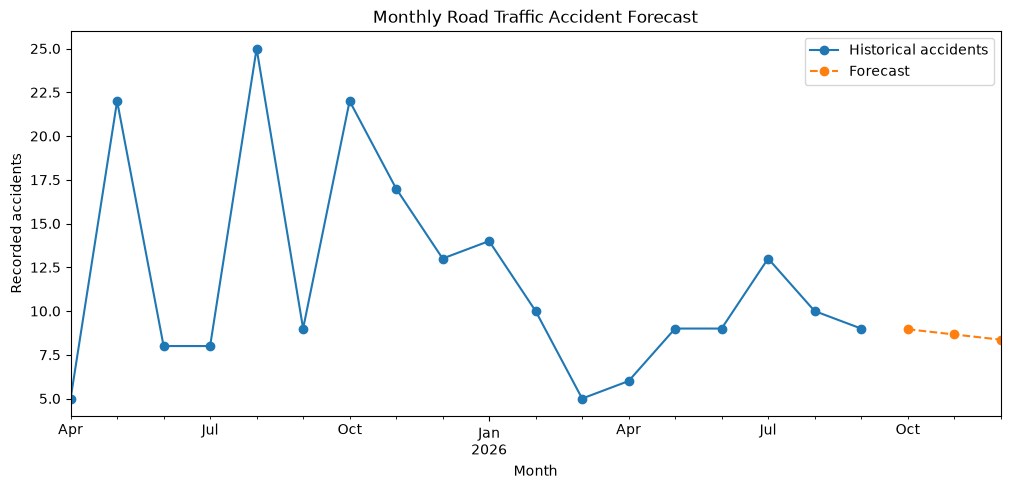

In [7]:
ax = monthly.plot(
    figsize=(12, 5),
    label="Historical accidents",
    marker="o"
)

forecast.plot(
    ax=ax,
    label="Forecast",
    marker="o",
    linestyle="--"
)

ax.set_title("Monthly Road Traffic Accident Forecast")
ax.set_xlabel("Month")
ax.set_ylabel("Recorded accidents")
ax.legend()